This notebook walks through the steps that the likelihood PID metric performs in order to showcase each step along the way. This will primarily be split into two sections: 

1. Bare Likelihood PID (No residual range correction), $\ell_0$

2. Residual range corrected Likelihood PID, $\ell$

In [61]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

import sys

sys.path.insert(0, "/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/root-6.28.12-vgs6mjswsg36hl3oarsrsyc2dcua6khe/lib/root")
import ROOT


import glob, os, re
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
from pyanalib.split_df_helpers import get_n_split
from pyanalib.pandas_helpers import multicol_merge

import makedf.llpid as llpid
import importlib
importlib.reload(llpid)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

import warnings
warnings.filterwarnings('ignore')


# 1. Bare Likelihood PID

In [174]:
file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_3.df"
params = llpid.LLPID_PARAMS
COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
PDG, TRUE_HYP = 2212, "p"                                      # (13, "mu") or (211, "pi") for another species

evt     = pd.read_hdf(file, key="/evt_0")
hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# Find a good demonstrative track where we can clearly see the benefit of residual range correction
pdg       = evt["pfp", "trk", "truth", "p", "pdg"]
contained = evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1
# stopped   = ~evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])
start_dist = np.sqrt(sum((evt["pfp", "trk", "start", a] - evt["pfp", "trk", "truth", "p", "start", a])**2 for a in "xyz"))
end_dist   = np.sqrt(sum((evt["pfp", "trk", "end", a]   - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))
good = (np.abs(pdg) == PDG) & contained  & (start_dist < 2) & (end_dist > 15)  & (evt["pfp", "trk", "len"] <25 )

trk    = evt.index[good][0]                                    # change [0] to look at another track
hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
print("track", trk, "  true pdg", pdg[trk])
print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
print("hits per plane:", [len(df) for df in hitdfs])


track (26, 9, 2, 0)   true pdg 2212
reco length 16.4 cm,  reco end is 16.2 cm from the true end
hits per plane: [11, 37, 46]


In [ ]:
# file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_10.df"
# params = llpid.LLPID_PARAMS
# COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
# PDG, TRUE_HYP = 2212, "p"                                      # (13, "mu") or (211, "pi") for another species

# evt     = pd.read_hdf(file, key="/evt_0")
# hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# # a contained, stopping track whose reco start is on the true start, but whose reco end stops
# # 5-20 cm short of the true end: the rr correction should find that missing length
# pdg       = evt["pfp", "trk", "truth", "p", "pdg"]
# contained = evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1
# # stopped   = ~evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])
# start_dist = np.sqrt(sum((evt["pfp", "trk", "start", a] - evt["pfp", "trk", "truth", "p", "start", a])**2 for a in "xyz"))
# end_dist   = np.sqrt(sum((evt["pfp", "trk", "end", a]   - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))
# good = (np.abs(pdg) == PDG) & contained  & (start_dist < 2) & (end_dist > 15) & (end_dist < 30) & (evt["pfp", "trk", "len"] > 30)

# trk    = evt.index[good][0]                                    # change [0] to look at another track
# hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
# print("track", trk, "  true pdg", pdg[trk])
# print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
# print("hits per plane:", [len(df) for df in hitdfs])


track (43, 3, 1, 1)   true pdg 2212
reco length 67.4 cm,  reco end is 22.7 cm from the true end
hits per plane: [38, 125, 105]


usable hits per plane: [7, 31, 39]   total: 77


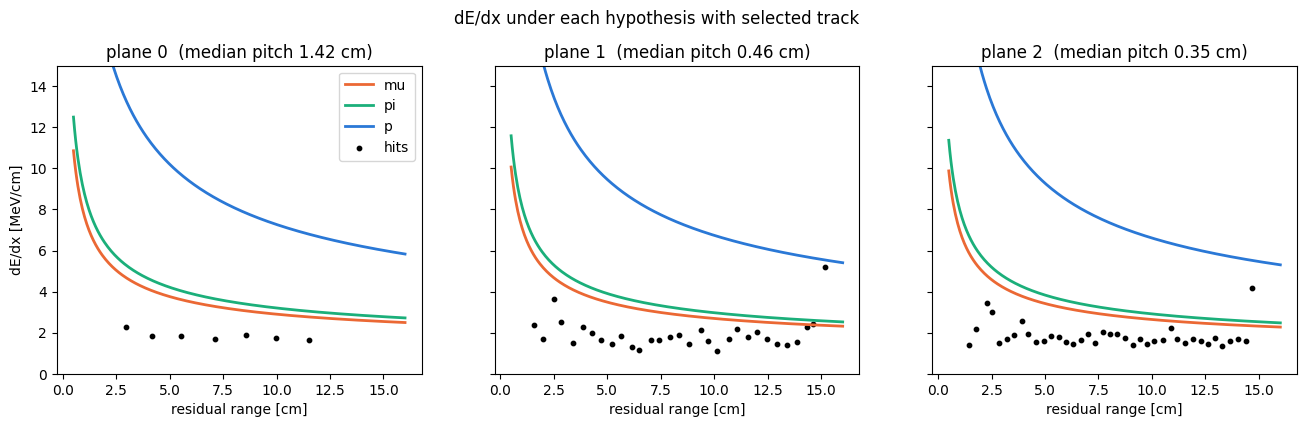

In [175]:
tracks = llpid._track_index(hitdfs)
planes = [llpid._prepare_plane(df, tracks, llpid._plane_of(df, i, len(hitdfs)), "dedx", params)
          for i, df in enumerate(hitdfs)]
n_hits = sum(h["n_usable"] for h in planes)
print("usable hits per plane:", [int(h["n_usable"][0]) for h in planes], "  total:", int(n_hits[0]))


rr_grid = np.linspace(0.5, max(hits["rr"].max() for hits in planes), 300)

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for hits, a in zip(planes, ax):
    pitch = np.median(hits["pitch"])
    for hyp in llpid.HYPS:
        KE = llpid._ke_from_rr(llpid._ke_table(hyp), rr_grid)
        xi, kappa, beta2, dedx_lam0 = llpid._pdf_params(KE, llpid.MASS[hyp], pitch)
        a.plot(rr_grid, dedx_lam0, color=COLOR[hyp], lw=2, label=hyp)
    a.scatter(hits["rr"][hits["usable"]], hits["dedx"][hits["usable"]], s=10, c="k", label="hits")
    a.set(xlabel="residual range [cm]", title=f"plane {hits['plane']}  (median pitch {pitch:.2f} cm)", ylim=(0, 15))
ax[0].set_ylabel("dE/dx [MeV/cm]"); ax[0].legend()
fig.suptitle("dE/dx under each hypothesis with selected track", y=1.02)
plt.show()


In [176]:
tables_bare = llpid._load_tables(params["tables_bare"])

per_hit = {}
for hyp in llpid.HYPS:
    frames = []
    for hits in planes:
        KE = llpid._ke_from_rr(llpid._ke_table(hyp), hits["rr"])
        xi, kappa, beta2, dedx_lam0 = llpid._pdf_params(KE, llpid.MASS[hyp], hits["pitch"])
        table = llpid._table_for(tables_bare, hits["plane"], hyp)
        pdf   = llpid._hit_pdf(hits["dedx"], hits["pitch"], KE, llpid.MASS[hyp], table)
        frames.append(pd.DataFrame({"plane": hits["plane"], "rr": hits["rr"], "dedx": hits["dedx"], "KE": KE,
                                    "lambda": (hits["dedx"] - dedx_lam0) / xi,      # same line as in _hit_pdf
                                    "kappa": kappa, "beta2": beta2,
                                    "pdf": pdf, "-2ln(pdf)": -2 * np.log(pdf)})[hits["usable"]])
    per_hit[hyp] = pd.concat(frames, ignore_index=True)

# per_hit[TRUE_HYP].head(21)

per_hit['mu'].head(21)


,plane,rr,dedx,KE,lambda,kappa,beta2,pdf,-2ln(pdf)
0,0,2.948086,2.264830,22.510298,-8.076287,0.873745,0.320415,0.235421,2.892758
1,0,4.175017,1.855373,27.669291,-8.479206,0.602241,0.371989,0.164478,3.609953
2,0,5.546439,1.813094,32.832416,-7.809108,0.444878,0.417942,0.194014,3.279646
3,0,7.107652,1.688022,38.211915,-7.645250,0.342798,0.460656,0.115844,4.311025
4,0,8.581141,1.904195,42.952035,-5.973083,0.281669,0.494514,0.174824,3.487945
5,0,9.959566,1.743048,47.167197,-6.347838,0.242662,0.522013,0.263234,2.669423
6,0,11.495135,1.646972,51.669197,-6.455884,0.210661,0.548978,0.276831,2.568694
7,1,1.565675,2.353066,15.575193,-8.599145,0.567979,0.240440,0.051863,5.918318
8,1,1.984485,1.712980,17.863208,-9.717042,0.439448,0.268318,0.030775,6.962087
9,1,2.527491,3.618832,20.566269,-3.218152,0.338212,0.299320,0.239937,2.854756


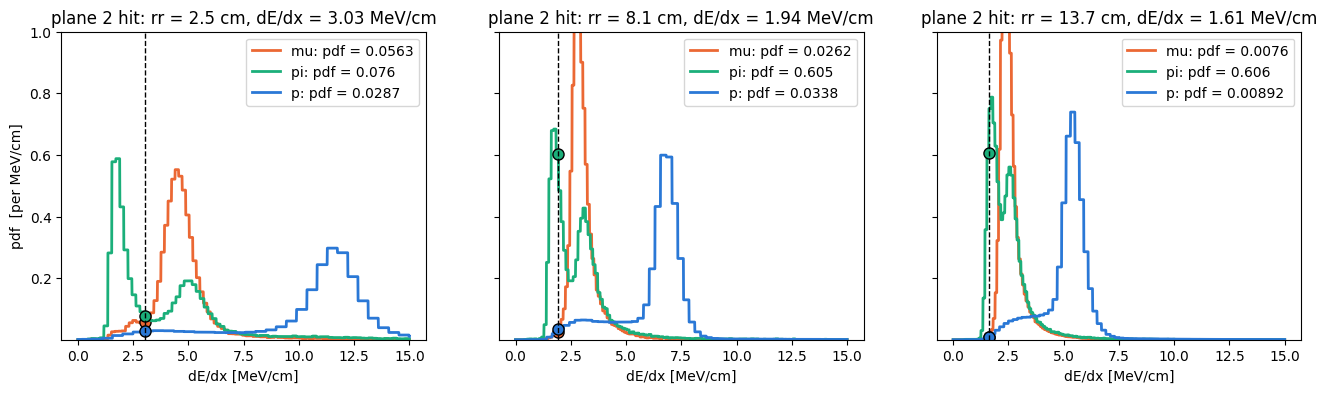


  mu
    plane         rr      dedx         KE    lambda     kappa     beta2       pdf  -2ln(pdf)
41      2   2.523384  3.027476  20.546718 -4.789857  0.255223  0.299103  0.056319   5.753445
57      2   8.052000  1.940591  41.281080 -4.585766  0.072814  0.482952  0.026222   7.282292
73      2  13.659505  1.605921  57.744779 -4.736505  0.040975  0.581893  0.007597   9.760125

  pi
    plane         rr      dedx         KE    lambda     kappa     beta2       pdf  -2ln(pdf)
41      2   2.523384  3.027476  23.091184 -5.893122  0.343707  0.263765  0.076048   5.152789
57      2   8.052000  1.940591  45.949522 -5.535894  0.098330  0.434014  0.604601   1.006373
73      2  13.659505  1.605921  63.820309 -5.555582  0.055579  0.529105  0.606039   1.001622

  p
    plane         rr      dedx          KE     lambda     kappa     beta2       pdf  -2ln(pdf)
41      2   2.523384  3.027476   52.683133 -10.922657  2.698140  0.103502  0.028685   7.102785
57      2   8.052000  1.940591  101.393859 -10.45

In [177]:
# three collection-plane hits: near the stopping end, mid-track, far from the end
hits  = planes[2]
used  = np.flatnonzero(hits["usable"])
picks = used[[len(used) // 10, len(used) // 2, 9 * len(used) // 10]]   # 10%, 50% and 90% of the way along the track
dedx_grid = np.linspace(0, 15, 1500)

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for i, a in zip(picks, ax):
    rr, dedx, pitch = hits["rr"][i], hits["dedx"][i], hits["pitch"][i]
    for hyp in llpid.HYPS:
        KE    = llpid._ke_from_rr(llpid._ke_table(hyp), rr)
        table = llpid._table_for(tables_bare, hits["plane"], hyp)
        curve = llpid._hit_pdf(dedx_grid, pitch, KE, llpid.MASS[hyp], table)   # the pdf this hit is read from
        value = llpid._hit_pdf(dedx, pitch, KE, llpid.MASS[hyp], table)        # where the hit lands on it
        a.plot(dedx_grid, curve, color=COLOR[hyp], lw=2, label=f"{hyp}: pdf = {float(value):.3g}")
        a.plot(dedx, value, "o", ms=8, color=COLOR[hyp], markeredgecolor="k")
    a.axvline(dedx, color="k", lw=1, ls="--")
    a.set(xlabel="dE/dx [MeV/cm]", yscale="linear", ylim=(1e-4, 1),
          title=f"plane {hits['plane']} hit: rr = {rr:.1f} cm, dE/dx = {dedx:.2f} MeV/cm")
    a.legend()
ax[0].set_ylabel("pdf  [per MeV/cm]")
plt.show()

# the same hits in the per-hit table from 1c
for hyp in llpid.HYPS:
    t = per_hit[hyp]
    print("\n ",hyp); print(t[(t["plane"] == hits["plane"]) & t["rr"].isin(hits["rr"][picks])].to_string())
    


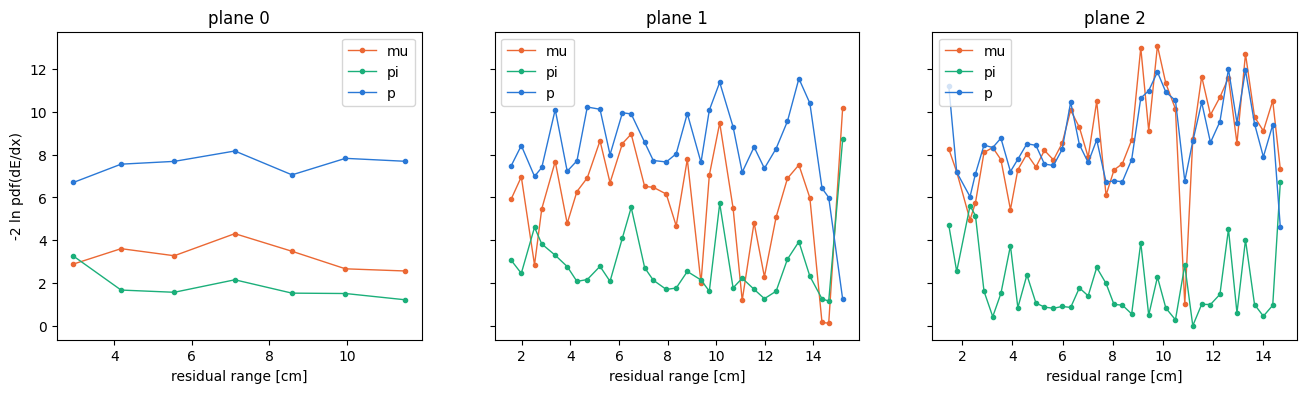

In [178]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for plane, a in enumerate(ax):
    for hyp in llpid.HYPS:
        h = per_hit[hyp][per_hit[hyp]["plane"] == plane]
        a.plot(h["rr"], h["-2ln(pdf)"], "o-", ms=3, lw=1, color=COLOR[hyp], label=hyp)
    a.set(xlabel="residual range [cm]", title=f"plane {plane}")
    a.legend()
ax[0].set_ylabel("-2 ln pdf(dE/dx)"); 
plt.show()


In [179]:
for hyp in llpid.HYPS:
    print(hyp)
    for hits in planes:
        by_hand = per_hit[hyp].loc[per_hit[hyp]["plane"] == hits["plane"], "-2ln(pdf)"].sum()
        n, ell_plane = llpid._track_ell(hits, tables_bare, hyp)
        print(f"   plane {hits['plane']}: {int(n[0]):4d} hits   by hand {by_hand:9.2f}   _track_ell   {ell_plane[0]:9.2f}")
    by_hand = per_hit[hyp]["-2ln(pdf)"].sum()
    print(f"   all planes        by hand {by_hand:9.2f}   _ell_at_zero {llpid._ell_at_zero(planes, tables_bare, hyp)[0]:9.2f}")

llpid.likelihood(hitdfs, rrcorr=False, params=params)


mu
   plane 0:    7 hits   by hand     22.82   _track_ell       22.82
   plane 1:   31 hits   by hand    179.61   _track_ell      179.61
   plane 2:   39 hits   by hand    338.44   _track_ell      338.44
   all planes        by hand    540.87   _ell_at_zero    540.87
pi
   plane 0:    7 hits   by hand     12.95   _track_ell       12.95
   plane 1:   31 hits   by hand     88.34   _track_ell       88.34
   plane 2:   39 hits   by hand     76.05   _track_ell       76.05
   all planes        by hand    177.34   _ell_at_zero    177.34
p
   plane 0:    7 hits   by hand     52.68   _track_ell       52.68
   plane 1:   31 hits   by hand    260.15   _track_ell      260.15
   plane 2:   39 hits   by hand    339.15   _track_ell      339.15
   all planes        by hand    651.97   _ell_at_zero    651.97


,,,,ell0_mu,ell0_pi,ell0_p,nhits_mu,nhits_pi,nhits_p
__ntuple,entry,rec.slc..index,rec.slc.reco.pfp..index,,,,,,
26,9,2,0,540.867064,177.336003,651.974572,77.0,77.0,77.0


# 2. Residual Range Corrected Likelihood

mu  dL = 0:   540.87    best dL =  109.0 cm:     66.23 hits + 22.62 prior =    88.85
pi  dL = 0:   471.47    best dL =  145.0 cm:     67.23 hits + 12.73 prior =    79.96
 p  dL = 0:   779.68    best dL =  593.0 cm:     80.80 hits + 27.06 prior =   107.86


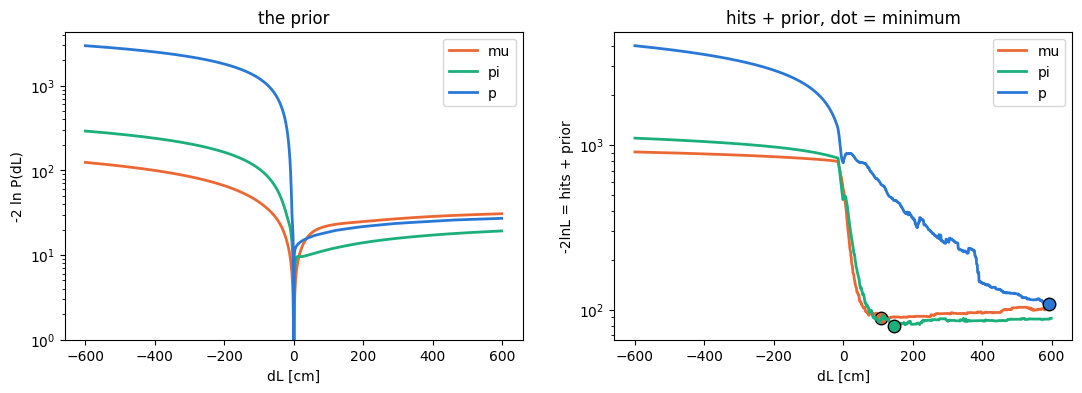

In [180]:
tables = llpid._load_tables(params["tables"])
priors, dl_min = llpid._load_priors(params["prior_file"])

scan = {}
for hyp in llpid.HYPS:
    dls = np.arange(dl_min[hyp], params["scan_max"], 1.0)
    data_term = []
    for dl in dls:
        total = 0.0
        for hits in planes:
            n, ell_plane = llpid._track_ell(hits, tables, hyp, offset=dl)
            total += np.nan_to_num(ell_plane[0])
        data_term.append(total)
    data_term  = np.array(data_term)
    prior_term = llpid._prior_charge(priors[hyp], dls)
    scan[hyp]  = {"dl": dls, "data": data_term, "prior": prior_term, "total": data_term + prior_term}

    best = np.argmin(scan[hyp]["total"])
    print(f"{hyp:>2}  dL = 0: {data_term[dls == 0][0]:8.2f}    best dL = {dls[best]:6.1f} cm:  "
          f"{data_term[best]:8.2f} hits + {prior_term[best]:5.2f} prior = {scan[hyp]['total'][best]:8.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for hyp in llpid.HYPS:
    s = scan[hyp]
    best = np.argmin(s["total"])
    ax[0].plot(s["dl"], s["prior"], color=COLOR[hyp], lw=2, label=hyp)
    ax[1].plot(s["dl"], s["total"], color=COLOR[hyp], lw=2, label=hyp)
    ax[1].plot(s["dl"][best], s["total"][best], "o", ms=9, color=COLOR[hyp], markeredgecolor="k")
ax[0].set(xlabel="dL [cm]", ylabel="-2 ln P(dL)", title="the prior", yscale='log')
ax[1].set(xlabel="dL [cm]", ylabel="-2lnL = hits + prior", yscale="log", title="hits + prior, dot = minimum")
ax[0].legend(); ax[1].legend()
plt.show()


coarse grid: 241 points from -600.0 to 600.0 cm in 5.0 cm steps
fine grid  : from 575.0 to 615.0 cm in 1.0 cm steps
minimum    : dL = 615.0 cm,  -2lnL = 107.04
zero_ell   : -2lnL at dL = 0 with the rr-corr table = 779.68


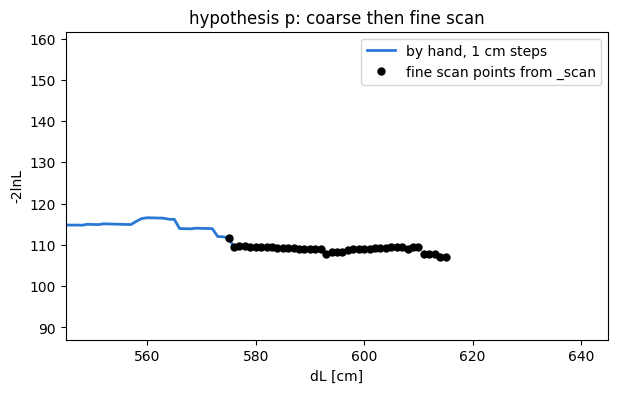

In [181]:
hyp    = TRUE_HYP
step   = params["scan_coarse"]
coarse = np.arange(dl_min[hyp], params["scan_max"] + step, step)
reach  = params["fine_steps"] * step
fine   = np.arange(-reach, reach + params["scan_fine"], params["scan_fine"])

fine_ell, fine_dl, zero_ell = llpid._scan(planes, tables, hyp, coarse, fine, priors[hyp], len(tracks), flipped=False)
print("coarse grid:", len(coarse), "points from", coarse[0], "to", coarse[-1], "cm in", step, "cm steps")
print("fine grid  : from", fine_dl[0, 0], "to", fine_dl[-1, 0], "cm in", params["scan_fine"], "cm steps")
print("minimum    : dL =", fine_dl[np.nanargmin(fine_ell[:, 0]), 0], "cm,  -2lnL =", round(np.nanmin(fine_ell[:, 0]), 2))
print("zero_ell   : -2lnL at dL = 0 with the rr-corr table =", round(zero_ell[0], 2))

s = scan[hyp]
plt.figure(figsize=(7, 4))
plt.plot(s["dl"], s["total"], color=COLOR[hyp], lw=2, label="by hand, 1 cm steps")
plt.plot(fine_dl[:, 0], fine_ell[:, 0], "o", ms=5, color="k", label="fine scan points from _scan")
plt.xlim(fine_dl[0, 0] - 30, fine_dl[-1, 0] + 30)
plt.ylim(np.nanmin(fine_ell) - 20, np.nanmax(fine_ell) + 50)
plt.xlabel("dL [cm]"); plt.ylabel("-2lnL"); plt.title(f"hypothesis {hyp}: coarse then fine scan"); plt.legend()
plt.show()


In [182]:
edge_lo, edge_hi = llpid._well_edges(fine_ell)
ell_min = np.nanmin(fine_ell, axis=0)
print("left edge  - minimum:", round((edge_lo - ell_min)[0], 2))
print("right edge - minimum:", round((edge_hi - ell_min)[0], 2))
print("flat_abs            :", params["flat_abs"])
print("flattened, so dL is set to 0:", ((edge_lo - ell_min) < params["flat_abs"])[0] or ((edge_hi - ell_min) < params["flat_abs"])[0])


left edge  - minimum: 2.96
right edge - minimum: 0.42
flat_abs            : 10.0
flattened, so dL is set to 0: True


In [183]:
rev_ell, rev_dl, rev_zero = llpid._scan(planes, tables, hyp, coarse, fine, priors[hyp], len(tracks), flipped=True)
fwd_min, rev_min = np.nanmin(fine_ell[:, 0]), np.nanmin(rev_ell[:, 0])
print(f"forward  best -2lnL {fwd_min:8.2f} at dL = {fine_dl[np.nanargmin(fine_ell[:, 0]), 0]:6.1f} cm")
print(f"reversed best -2lnL {rev_min:8.2f} at dL = {rev_dl[np.nanargmin(rev_ell[:, 0]), 0]:6.1f} cm")
print(f"reversed has to win by flip_margin = {params['flip_margin']}:  flip = {fwd_min - rev_min > params['flip_margin']}")


forward  best -2lnL   107.04 at dL =  615.0 cm
reversed best -2lnL   108.38 at dL =  589.0 cm
reversed has to win by flip_margin = 25.0:  flip = False


In [184]:
fits = llpid._fit_dl(planes, tables, priors, dl_min, n_hits, params, llpid.HYPS)
pd.DataFrame({hyp: {name: fits[hyp][name][0] for name in ("cost", "dl", "flip", "fitok", "flattened", "onedge")}
              for hyp in llpid.HYPS})


,mu,pi,p
cost,513.789106,433.828635,779.677019
dl,0.0,0.0,0.0
flip,True,True,False
fitok,False,False,False
flattened,True,True,True
onedge,False,False,False


In [185]:
lldf = llpid.likelihood(hitdfs, rrcorr=True, params=params)
pd.DataFrame({"ell0 (bare)":  [lldf["ell0_" + h].iloc[0] for h in llpid.HYPS],
              "ell (dL fit)": [lldf["ell_" + h].iloc[0] for h in llpid.HYPS],
              "dL [cm]":      [lldf["dl_" + h].iloc[0] for h in llpid.HYPS]}, index=llpid.HYPS)


,ell0 (bare),ell (dL fit),dL [cm]
mu,540.867064,513.789106,0.0
pi,177.336003,433.828635,0.0
p,651.974572,779.677019,0.0


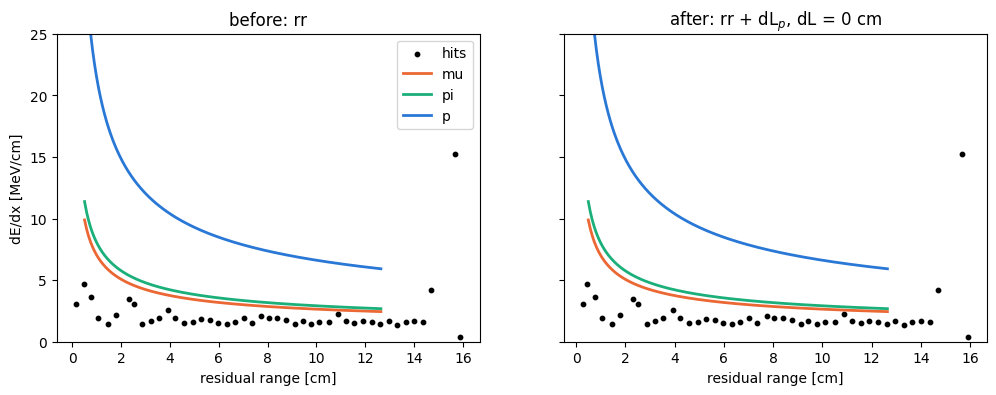

In [186]:
hdf  = hitdfs[2]
dl   = lldf["dl_" + TRUE_HYP].iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, rr, title in [(ax[0], hdf["rr"], "before: rr"),
                     (ax[1], llpid.rr_corr(hdf, lldf, TRUE_HYP), f"after: rr + dL$_{{{TRUE_HYP}}}$, dL = {dl:.0f} cm")]:
    a.scatter(rr, hdf["dedx"], s=10, c="k", label="hits")
    for h in llpid.HYPS:
        rr_grid = np.linspace(0.5, c["rr"].max()+dl, 300)
        KE = llpid._ke_from_rr(llpid._ke_table(h), rr_grid)
        a.plot(rr_grid, llpid._pdf_params(KE, llpid.MASS[h], pitch)[3], color=COLOR[h], lw=2, label=h)
    a.set(xlabel="residual range [cm]", title=title, ylim=(0, 25))
ax[0].set_ylabel("dE/dx [MeV/cm]"); ax[0].legend()
plt.show()
